# IT2226 · Member 4 · Custom CNN

Train and evaluate a six-class dental image classifier (`custom_cnn`) in Google Colab on the fixed team dataset split (`school_oral_training_v1`).

**Notebook flow:**
1. **Connect Google Drive** (`drive.mount('/content/drive')`)
2. **Settings and libraries** (hyperparameters, seed, GPU device, output folder)
3. **Exploratory Data Analysis (EDA) & Data Loading** (fixed train/val/test counts, imbalance chart, sample grid)
4. **Build Baseline Custom CNN & Loss Function** (4-block CNN + class-weighted `CrossEntropyLoss`)
5. **Run 1: Baseline Custom CNN** (original crop pipeline from `00_training_template.ipynb`)
6. **Run 2: Custom CNN with Team `05a`/`06` Photometric Lab + Letterbox Augmentation** (train-only Lab target calibration & style shift + deterministic letterbox evaluation + BatchNorm + comparison)


## 1. Connect Google Drive


In [1]:
from pathlib import Path
from google.colab import drive

# Mounts your entire Google Drive under /content/drive in this Colab session.
drive.mount('/content/drive')

# Locate the shared group folder via the shortcut in My Drive.
ROOT = Path('/content/drive/MyDrive/26S2-AIDL-Group-7-ToothPic')
if not ROOT.exists():
    ROOT = Path('/content/drive/MyDrive/26S2-AIDL-Group-7')

DATA = ROOT / 'dataset/school_oral_training_v1'
assert (DATA / 'train').exists(), (
    f'Cannot find dataset at {DATA}. '
    'Add a shortcut to "26S2-AIDL-Group-7-ToothPic" in your My Drive first.'
)
print('Project root:', ROOT)
print('Dataset path:', DATA)


Mounted at /content/drive
Project root: /content/drive/MyDrive/26S2-AIDL-Group-7-ToothPic
Dataset path: /content/drive/MyDrive/26S2-AIDL-Group-7-ToothPic/dataset/school_oral_training_v1


## 2. Settings and libraries


In [2]:
import csv
import io
import json
import random

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image, ImageOps
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms
from tqdm.auto import tqdm

# Core settings (shared dataset split and seed across team notebooks)
MODEL = 'custom_cnn'
RUN_NAME = 'member_4_custom_cnn'
EPOCHS = 12
IMPROVED_EPOCHS = 20
BATCH_SIZE = 32
LEARNING_RATE = 0.0003
IMPROVED_LR = 0.001
IMAGE_SIZE = 224
SEED = 42
NUM_WORKERS = 2

# Photometric Lab + letterbox settings adapted from team notebooks 05a and 06
PAD_COLOR = (128, 128, 128)
JPEG_QUALITY = 90
SAMPLE_PER_CLASS = 80
STYLE_PROB = 0.75
AB_PERCENTILES = (0.10, 0.90)
MAX_AB_SHIFT = 8.0

# Fix random seeds so results are reproducible
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
SAVE_DIR = ROOT / 'models' / RUN_NAME
SAVE_DIR.mkdir(parents=True, exist_ok=True)
print('Device:', DEVICE, '| Model:', MODEL, '| Save dir:', SAVE_DIR)


Device: cuda | Model: custom_cnn | Save dir: /content/drive/MyDrive/26S2-AIDL-Group-7-ToothPic/models/member_4_custom_cnn


## 3. Exploratory Data Analysis (EDA) & Baseline Data Loading


Classes (6): ['calculus', 'caries', 'hypodontia', 'mouth_ulcer', 'normal', 'tooth_discoloration']
Total images: 3795 (3035 train / 378 val / 382 test)

Class                    Train     Val    Test   Total
------------------------------------------------------
calculus                   642      80      80     802
caries                     155      19      20     194
hypodontia                 979     122     123    1224
mouth_ulcer                194      24      25     243
normal                     227      28      29     284
tooth_discoloration        838     105     105    1048


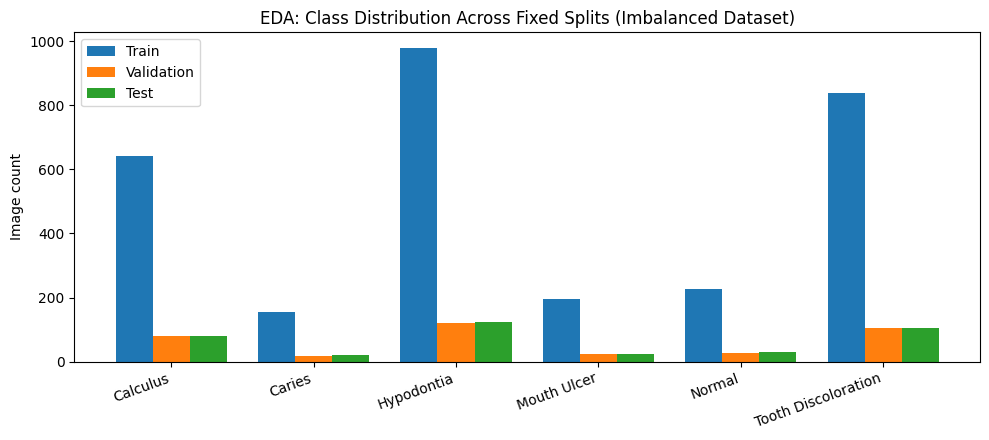

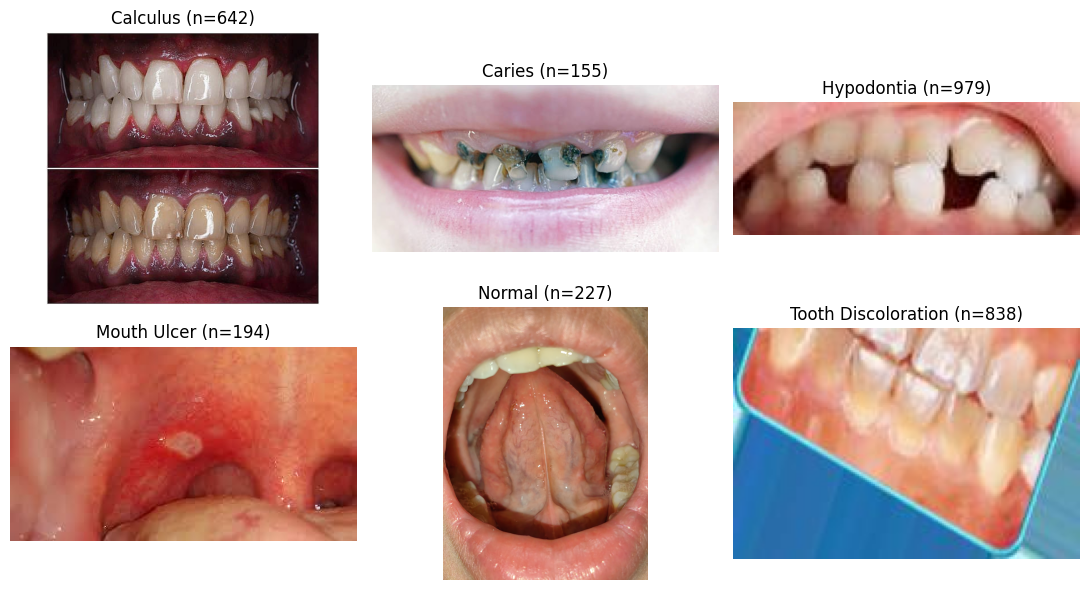

In [3]:
# ImageNet RGB mean/std normalization used consistently across team notebooks
normalize = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])

# Baseline training transforms (matching 00_training_template.ipynb)
train_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomCrop(IMAGE_SIZE),
    transforms.RandomRotation(8),
    transforms.ColorJitter(brightness=0.12, contrast=0.12),
    transforms.ToTensor(),
    normalize,
])

# Deterministic validation/test transforms for Run 1
val_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    normalize,
])

# Load the exact pre-split folders (never re-split so teammates stay comparable)
train_data = datasets.ImageFolder(DATA / 'train', transform=train_transform)
val_data = datasets.ImageFolder(DATA / 'val', transform=val_transform)
test_data = datasets.ImageFolder(DATA / 'test', transform=val_transform)

with open(DATA / 'class_to_idx.json', encoding='utf-8') as f:
    class_to_idx = json.load(f)
assert train_data.class_to_idx == val_data.class_to_idx == test_data.class_to_idx == class_to_idx
names = train_data.classes

train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, persistent_workers=(NUM_WORKERS > 0))
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, persistent_workers=(NUM_WORKERS > 0))
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, persistent_workers=(NUM_WORKERS > 0))

# --- EDA 1: Class distribution across train / val / test ---
train_counts = np.bincount(train_data.targets, minlength=len(names))
val_counts = np.bincount(val_data.targets, minlength=len(names))
test_counts = np.bincount(test_data.targets, minlength=len(names))

print(f'Classes ({len(names)}): {names}')
print(f'Total images: {len(train_data) + len(val_data) + len(test_data)} '
      f'({len(train_data)} train / {len(val_data)} val / {len(test_data)} test)\n')
print(f'{"Class":<22} {"Train":>7} {"Val":>7} {"Test":>7} {"Total":>7}')
print('-' * 54)
for idx, cls_name in enumerate(names):
    total = int(train_counts[idx] + val_counts[idx] + test_counts[idx])
    print(f'{cls_name:<22} {train_counts[idx]:>7} {val_counts[idx]:>7} {test_counts[idx]:>7} {total:>7}')

# Plot grouped bar chart of class counts
x = np.arange(len(names))
width = 0.26
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(x - width, train_counts, width, label='Train')
ax.bar(x, val_counts, width, label='Validation')
ax.bar(x + width, test_counts, width, label='Test')
ax.set_xticks(x)
ax.set_xticklabels([n.replace('_', ' ').title() for n in names], rotation=20, ha='right')
ax.set_ylabel('Image count')
ax.set_title('EDA: Class Distribution Across Fixed Splits (Imbalanced Dataset)')
ax.legend()
plt.tight_layout()
plt.savefig(SAVE_DIR / 'eda_class_distribution.png', dpi=140)
plt.show()

# --- EDA 2: Sample one training image per class ---
fig, axes = plt.subplots(2, 3, figsize=(11, 6))
for ax, class_id in zip(axes.flat, range(len(names))):
    choices = [path for path, label in train_data.samples if label == class_id]
    with Image.open(random.choice(choices)) as image:
        ax.imshow(image.convert('RGB'))
    ax.set_title(f"{names[class_id].replace('_', ' ').title()} (n={train_counts[class_id]})")
    ax.axis('off')
plt.tight_layout()
plt.show()


## 4. Build Baseline Custom CNN & Loss Function


In [4]:
def build_model(name, n_classes):
    '''Build one of the four team model architectures.'''
    if name == 'resnet18':
        net = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        net.fc = nn.Linear(net.fc.in_features, n_classes)
    elif name == 'mobilenet_v3_small':
        net = models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.DEFAULT)
        net.classifier[-1] = nn.Linear(net.classifier[-1].in_features, n_classes)
    elif name == 'efficientnet_b0':
        net = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
        net.classifier[-1] = nn.Linear(net.classifier[-1].in_features, n_classes)
    elif name == 'custom_cnn':
        # 4-block CNN trained from scratch: 3 -> 32 -> 64 -> 128 -> 256 channels
        net = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(128, 256, kernel_size=3, padding=1), nn.ReLU(),
            nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3),
            nn.Linear(256, n_classes),
        )
    else:
        raise ValueError(f'Unknown model: {name}')
    return net


baseline_model = build_model(MODEL, len(names)).to(DEVICE)

# Inverse-frequency class weights penalize mistakes on minority classes (e.g., caries) more heavily
counts = torch.bincount(torch.tensor(train_data.targets), minlength=len(names)).float()
class_weights = (counts.sum() / (len(names) * counts)).to(DEVICE)
loss_fn = nn.CrossEntropyLoss(weight=class_weights)
baseline_optimizer = torch.optim.AdamW(baseline_model.parameters(), lr=LEARNING_RATE)

print('Class weights:', dict(zip(names, [round(w, 3) for w in class_weights.tolist()])))
print('Baseline trainable parameters:', f'{sum(p.numel() for p in baseline_model.parameters() if p.requires_grad):,}')


Class weights: {'calculus': 0.788, 'caries': 3.263, 'hypodontia': 0.517, 'mouth_ulcer': 2.607, 'normal': 2.228, 'tooth_discoloration': 0.604}
Baseline trainable parameters: 389,958


## 5. Run 1: Baseline Custom CNN (Original Crop Pipeline)


[Baseline] Epoch 01/12 | train loss 1.755 | val loss 1.719 | val F1 0.135


[Baseline] Epoch 02/12 | train loss 1.614 | val loss 1.507 | val F1 0.273


[Baseline] Epoch 03/12 | train loss 1.537 | val loss 1.457 | val F1 0.316


[Baseline] Epoch 04/12 | train loss 1.520 | val loss 1.607 | val F1 0.250


[Baseline] Epoch 05/12 | train loss 1.469 | val loss 1.378 | val F1 0.392


[Baseline] Epoch 06/12 | train loss 1.447 | val loss 1.417 | val F1 0.358


... (2 outputs left out)

[Baseline] Epoch 09/12 | train loss 1.341 | val loss 1.279 | val F1 0.483


[Baseline] Epoch 10/12 | train loss 1.319 | val loss 1.220 | val F1 0.471


[Baseline] Epoch 11/12 | train loss 1.272 | val loss 1.125 | val F1 0.501


[Baseline] Epoch 12/12 | train loss 1.259 | val loss 1.146 | val F1 0.504


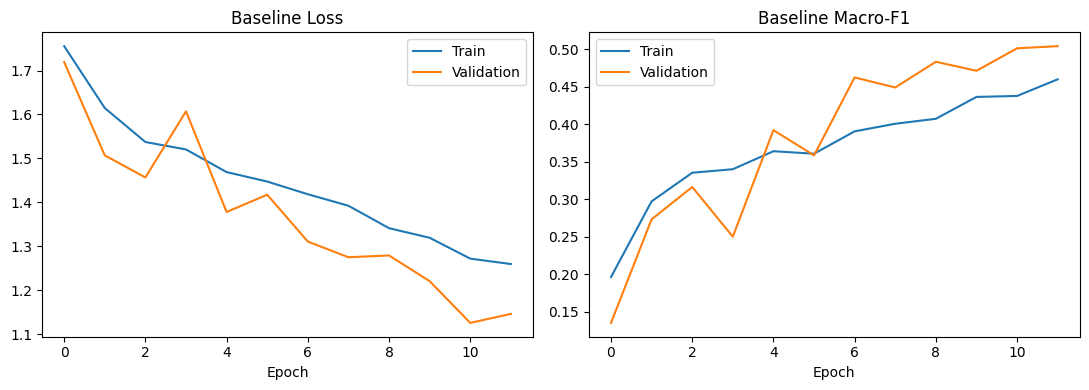

Baseline Test Acc: 0.547 | Test Macro-F1: 0.495 | Loss: 1.156
                     precision    recall  f1-score   support

           calculus      0.850     0.637     0.729        80
             caries      0.216     0.400     0.281        20
         hypodontia      0.813     0.496     0.616       123
        mouth_ulcer      0.235     0.800     0.364        25
             normal      0.414     0.414     0.414        29
tooth_discoloration      0.594     0.543     0.567       105

           accuracy                          0.547       382
          macro avg      0.520     0.548     0.495       382
       weighted avg      0.661     0.547     0.577       382



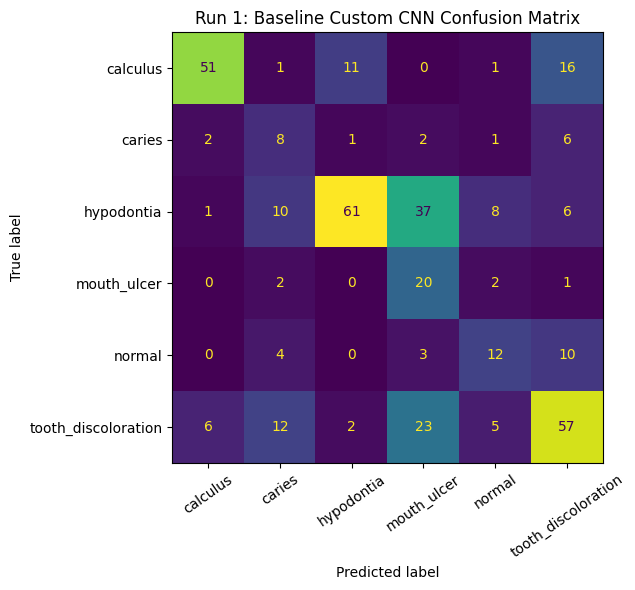

In [5]:
def run_epoch(net, loader, optimizer=None):
    '''Run one full pass over a DataLoader; updates weights only when optimizer is provided.'''
    training = optimizer is not None
    net.train(training)
    total_loss = 0.0
    actual, predicted = [], []

    for images, labels in tqdm(loader, leave=False, disable=not training):
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        with torch.set_grad_enabled(training):
            scores = net(images)
            loss = loss_fn(scores, labels)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
        total_loss += loss.item() * len(labels)
        actual.extend(labels.cpu().tolist())
        predicted.extend(scores.argmax(1).cpu().tolist())

    avg_loss = total_loss / len(loader.dataset)
    macro_f1 = f1_score(actual, predicted, labels=list(range(len(names))), average='macro', zero_division=0)
    return avg_loss, macro_f1, actual, predicted


baseline_best_f1 = -1.0
baseline_history = []
BASELINE_CKPT = SAVE_DIR / 'baseline_best.pt'

for epoch in range(1, EPOCHS + 1):
    train_loss, train_f1, _, _ = run_epoch(baseline_model, train_loader, baseline_optimizer)
    val_loss, val_f1, _, _ = run_epoch(baseline_model, val_loader)
    baseline_history.append({
        'epoch': epoch,
        'train_loss': train_loss,
        'val_loss': val_loss,
        'train_f1': train_f1,
        'val_f1': val_f1,
    })
    print(f'[Baseline] Epoch {epoch:02}/{EPOCHS} | train loss {train_loss:.3f} | '
          f'val loss {val_loss:.3f} | val F1 {val_f1:.3f}')
    if val_f1 > baseline_best_f1:
        baseline_best_f1 = val_f1
        torch.save({
            'state_dict': baseline_model.state_dict(),
            'model_name': MODEL,
            'class_to_idx': class_to_idx,
            'image_size': IMAGE_SIZE,
            'val_macro_f1': baseline_best_f1,
            'epoch': epoch,
        }, BASELINE_CKPT)

# Plot baseline learning curves
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot([x['train_loss'] for x in baseline_history], label='Train')
ax[0].plot([x['val_loss'] for x in baseline_history], label='Validation')
ax[0].set_title('Baseline Loss'); ax[0].set_xlabel('Epoch'); ax[0].legend()
ax[1].plot([x['train_f1'] for x in baseline_history], label='Train')
ax[1].plot([x['val_f1'] for x in baseline_history], label='Validation')
ax[1].set_title('Baseline Macro-F1'); ax[1].set_xlabel('Epoch'); ax[1].legend()
plt.tight_layout()
plt.savefig(SAVE_DIR / 'baseline_training_curves.png', dpi=140)
plt.show()

# Evaluate best baseline checkpoint on the held-out test set
ckpt = torch.load(BASELINE_CKPT, map_location=DEVICE, weights_only=True)
baseline_model.load_state_dict(ckpt['state_dict'])
base_test_loss, base_test_f1, base_actual, base_pred = run_epoch(baseline_model, test_loader)
base_test_acc = accuracy_score(base_actual, base_pred)

print(f'Baseline Test Acc: {base_test_acc:.3f} | Test Macro-F1: {base_test_f1:.3f} | Loss: {base_test_loss:.3f}')
print(classification_report(base_actual, base_pred, labels=list(range(len(names))),
                            target_names=names, digits=3, zero_division=0))

cm_base = confusion_matrix(base_actual, base_pred, labels=range(len(names)))
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay(cm_base, display_labels=names).plot(ax=ax, xticks_rotation=35, colorbar=False)
ax.set_title('Run 1: Baseline Custom CNN Confusion Matrix')
plt.tight_layout()
plt.savefig(SAVE_DIR / 'baseline_confusion_matrix.png', dpi=140)
plt.show()

base_report = classification_report(base_actual, base_pred, labels=list(range(len(names))),
                                    target_names=names, output_dict=True, zero_division=0)
with open(SAVE_DIR / 'baseline_metrics.json', 'w', encoding='utf-8') as f:
    json.dump({
        'model': 'custom_cnn_baseline',
        'best_val_macro_f1': baseline_best_f1,
        'test_accuracy': base_test_acc,
        'test_macro_f1': base_test_f1,
        'test_loss': base_test_loss,
        'classification_report': base_report,
    }, f, indent=2)


## 6. Run 2: Custom CNN with Team `05a`/`06` Photometric Lab + Letterbox Augmentation

Following the team's shortcut findings from notebooks `05`, `05a`, and `06`:
1. **Calibrate Lab targets on training images only:** Sample up to 80 training images per class, measure Lab `L` (lightness) and `a/b` (colour balance) statistics, and compute plausible target ranges without touching validation or test images.
2. **Train-only stochastic Lab style + letterbox + JPEG q90 (`DentalPreprocess`):** During training (`STYLE_PROB = 0.75`), shift `L` and `a/b` (capped at `MAX_AB_SHIFT = 8.0`) on photo pixels before placing on a neutral-grey 224×224 letterbox canvas and standardizing via JPEG q90. Validation and test use **deterministic clean letterbox + JPEG q90** (zero random colour shifts).
3. **Custom CNN improvement (`BatchNorm2d` + `CosineAnnealingLR`):** Add `nn.BatchNorm2d` after each `Conv2d` block so the from-scratch Custom CNN converges reliably under photometric augmentation over 20 epochs.


Calibrated mean L: (126.26583557128907, 145.11163330078125) | std L: (45.47286529541015, 57.86180362701416) | paired a/b targets: 331


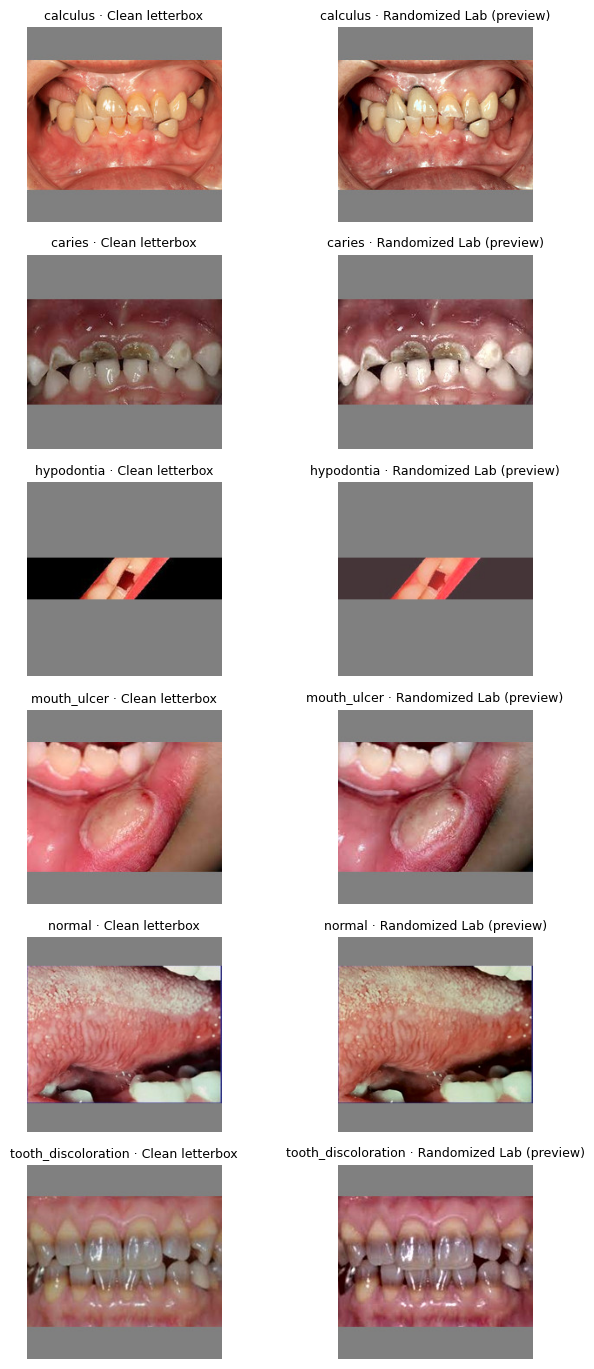

Improved Custom CNN trainable parameters: 390,438


[Photometric+BN] Epoch 01/20 | train loss 1.463 | val loss 1.242 | val F1 0.425


[Photometric+BN] Epoch 02/20 | train loss 1.183 | val loss 1.098 | val F1 0.502


[Photometric+BN] Epoch 03/20 | train loss 1.057 | val loss 1.427 | val F1 0.437


[Photometric+BN] Epoch 04/20 | train loss 0.940 | val loss 1.165 | val F1 0.504


[Photometric+BN] Epoch 05/20 | train loss 0.857 | val loss 0.685 | val F1 0.704


... (11 outputs left out)

[Photometric+BN] Epoch 17/20 | train loss 0.388 | val loss 0.416 | val F1 0.845


[Photometric+BN] Epoch 18/20 | train loss 0.396 | val loss 0.425 | val F1 0.817


[Photometric+BN] Epoch 19/20 | train loss 0.361 | val loss 0.420 | val F1 0.818


[Photometric+BN] Epoch 20/20 | train loss 0.368 | val loss 0.414 | val F1 0.819


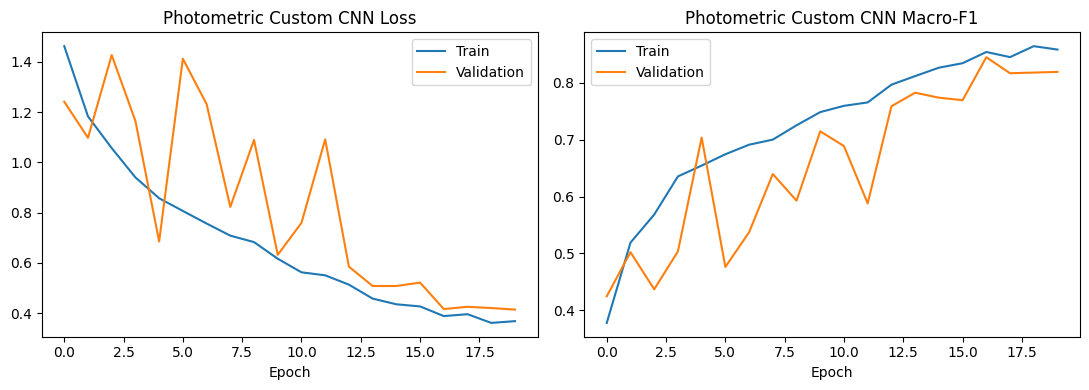

Improved Photometric Test Acc: 0.895 | Test Macro-F1: 0.814 | Loss: 0.436
                     precision    recall  f1-score   support

           calculus      0.937     0.925     0.931        80
             caries      0.533     0.400     0.457        20
         hypodontia      0.959     0.951     0.955       123
        mouth_ulcer      0.704     0.760     0.731        25
             normal      0.897     0.897     0.897        29
tooth_discoloration      0.891     0.933     0.912       105

           accuracy                          0.895       382
          macro avg      0.820     0.811     0.814       382
       weighted avg      0.892     0.895     0.893       382



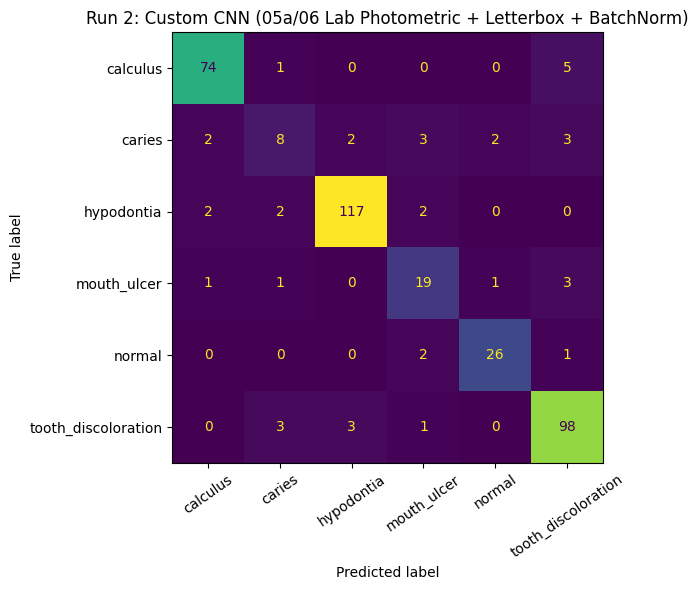


=== Run 1 (Original Crops) vs. Run 2 (05a/06 Photometric + Letterbox + BatchNorm) ===
Metric                              Run 1      Run 2      Delta
--------------------------------------------------------------
Test Accuracy                      0.5471     0.8953    +0.3482
Test Macro-F1                      0.4950     0.8137    +0.3187
Recall: calculus                   0.6375     0.9250    +0.2875
Recall: caries                     0.4000     0.4000    +0.0000
Recall: hypodontia                 0.4959     0.9512    +0.4553
Recall: mouth_ulcer                0.8000     0.7600    -0.0400
Recall: normal                     0.4138     0.8966    +0.4828
Recall: tooth_discoloration        0.5429     0.9333    +0.3904

Saved all outputs to: /content/drive/MyDrive/26S2-AIDL-Group-7-ToothPic/models/member_4_custom_cnn


In [6]:
# --- Step 6a: Calibrate Lab L/a/b ranges on training images only ---
def load_oriented_rgb(path):
    with Image.open(path) as im:
        return ImageOps.exif_transpose(im).convert('RGB')


def content_resize(image):
    return ImageOps.contain(image, (IMAGE_SIZE, IMAGE_SIZE), method=Image.Resampling.LANCZOS)


def put_on_canvas(content):
    # Pad resized photo onto a neutral-grey 224x224 square without cropping or stretching
    return ImageOps.pad(
        content, (IMAGE_SIZE, IMAGE_SIZE),
        method=Image.Resampling.LANCZOS, color=PAD_COLOR, centering=(0.5, 0.5)
    )


def lab_stats(image):
    arr = cv2.cvtColor(np.asarray(image), cv2.COLOR_RGB2LAB).astype(np.float32)
    return [float(arr[:, :, 0].mean()), float(arr[:, :, 0].std()),
            float(arr[:, :, 1].mean()), float(arr[:, :, 2].mean())]


EXTENSIONS = {'.jpg', '.jpeg', '.png', '.webp', '.bmp', '.tif', '.tiff'}
train_paths = {
    label: sorted(p for p in (DATA / 'train' / label).iterdir() if p.suffix.lower() in EXTENSIONS)
    for label in names
}

cal_rng = np.random.default_rng(SEED)
records = []
for label in names:
    images = train_paths[label]
    sample_idx = cal_rng.choice(len(images), size=min(SAMPLE_PER_CLASS, len(images)), replace=False)
    for j in tqdm(sample_idx, desc=f'Calibrate {label}', leave=False):
        content = content_resize(load_oriented_rgb(images[int(j)]))
        L_mean, L_std, a_mean, b_mean = lab_stats(content)
        records.append({'class': label, 'mean_L': L_mean, 'std_L': L_std, 'mean_a': a_mean, 'mean_b': b_mean})
cal = pd.DataFrame(records)


def plausible_range(series, a=0.35, b=0.65, min_width=12, lower=10, upper=245):
    lo, hi = np.quantile(series, [a, b])
    mid = (lo + hi) / 2
    half = max((hi - lo) / 2, min_width / 2)
    return float(max(lower, mid - half)), float(min(upper, mid + half))


MEAN_RANGE = plausible_range(cal.mean_L, min_width=18, lower=45, upper=210)
STD_RANGE = plausible_range(cal.std_L, min_width=12, lower=10, upper=95)
a_lo, a_hi = np.quantile(cal.mean_a, AB_PERCENTILES)
b_lo, b_hi = np.quantile(cal.mean_b, AB_PERCENTILES)
paired = cal[cal.mean_a.between(a_lo, a_hi) & cal.mean_b.between(b_lo, b_hi)]
AB_TARGETS = paired[['mean_a', 'mean_b']].to_numpy(dtype=np.float32)
print('Calibrated mean L:', MEAN_RANGE, '| std L:', STD_RANGE, '| paired a/b targets:', len(AB_TARGETS))


# --- Step 6b: Define 05a/06 random Lab transform and DentalPreprocess ---
def random_absolute_lab(content):
    '''Adjust Lab lightness and capped a/b colour balance on photo pixels (before padding).'''
    lab = cv2.cvtColor(np.asarray(content), cv2.COLOR_RGB2LAB).astype(np.float32)
    L, A, B = lab[:, :, 0], lab[:, :, 1], lab[:, :, 2]
    mean = float(L.mean())
    std = max(float(L.std()), 1e-3)
    target_mean = float(np.random.uniform(*MEAN_RANGE))
    target_std = float(np.random.uniform(*STD_RANGE))
    scale = float(np.clip(target_std / std, 0.65, 1.5))
    shift = float(np.clip(target_mean - mean, -45, 45))
    desired = (L - mean) * scale + mean + shift
    alpha = 1.0
    while np.mean((L + alpha * (desired - L) < 0) | (L + alpha * (desired - L) > 255)) > 0.03 and alpha > 0.07:
        alpha *= 0.70
    lab[:, :, 0] = np.clip(L + alpha * (desired - L), 0, 255)

    target_a, target_b = AB_TARGETS[np.random.randint(len(AB_TARGETS))]
    delta_a = float(np.clip(float(target_a) - float(A.mean()), -MAX_AB_SHIFT, MAX_AB_SHIFT))
    delta_b = float(np.clip(float(target_b) - float(B.mean()), -MAX_AB_SHIFT, MAX_AB_SHIFT))
    chroma_alpha = 1.0
    while np.mean((A + chroma_alpha * delta_a < 0) | (A + chroma_alpha * delta_a > 255) |
                  (B + chroma_alpha * delta_b < 0) | (B + chroma_alpha * delta_b > 255)) > 0.01 and chroma_alpha > 0.05:
        chroma_alpha *= 0.75
    lab[:, :, 1] = np.clip(A + chroma_alpha * delta_a, 0, 255)
    lab[:, :, 2] = np.clip(B + chroma_alpha * delta_b, 0, 255)
    arr = cv2.cvtColor(lab.astype(np.uint8), cv2.COLOR_LAB2RGB)
    return Image.fromarray(arr)


class DentalPreprocess:
    '''Team 06 preprocessing: train-only Lab style + letterbox + JPEG q90; clean letterbox for val/test.'''
    def __init__(self, training):
        self.training = training
        self.to_tensor = transforms.Compose([
            transforms.ToTensor(),
            normalize,
        ])

    def image_view(self, image, force_style=None):
        content = content_resize(image.convert('RGB'))
        use_style = ((np.random.random() < STYLE_PROB) if force_style is None else bool(force_style)) if self.training else False
        if use_style:
            content = random_absolute_lab(content)
        square = put_on_canvas(content)
        buf = io.BytesIO()
        square.save(buf, format='JPEG', quality=JPEG_QUALITY, subsampling=0)
        buf.seek(0)
        with Image.open(buf) as compressed:
            return compressed.convert('RGB').copy()

    def __call__(self, image):
        return self.to_tensor(self.image_view(image))


photo_train_transform = DentalPreprocess(training=True)
photo_clean_transform = DentalPreprocess(training=False)

# Save clean vs Lab-styled preview grid
fig, axes = plt.subplots(len(names), 2, figsize=(7.5, 2.3 * len(names)))
for i, label in enumerate(names):
    original = load_oriented_rgb(train_paths[label][0])
    clean_view = photo_clean_transform.image_view(original)
    styled_view = photo_train_transform.image_view(original, force_style=True)
    axes[i, 0].imshow(clean_view)
    axes[i, 1].imshow(styled_view)
    axes[i, 0].set_title(f'{label} · Clean letterbox', fontsize=9)
    axes[i, 1].set_title(f'{label} · Randomized Lab (preview)', fontsize=9)
    axes[i, 0].axis('off')
    axes[i, 1].axis('off')
plt.tight_layout()
plt.savefig(SAVE_DIR / 'preview.png', dpi=125)
plt.show()


# --- Step 6c: Build DataLoaders and Improved Custom CNN (with BatchNorm2d) ---
def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % (2**32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)


photo_train_data = datasets.ImageFolder(DATA / 'train', transform=photo_train_transform, loader=load_oriented_rgb)
photo_val_data = datasets.ImageFolder(DATA / 'val', transform=photo_clean_transform, loader=load_oriented_rgb)
photo_test_data = datasets.ImageFolder(DATA / 'test', transform=photo_clean_transform, loader=load_oriented_rgb)

g = torch.Generator().manual_seed(SEED)
photo_train_loader = DataLoader(photo_train_data, batch_size=BATCH_SIZE, shuffle=True,
                                num_workers=NUM_WORKERS, worker_init_fn=seed_worker, generator=g,
                                persistent_workers=(NUM_WORKERS > 0))
photo_val_loader = DataLoader(photo_val_data, batch_size=BATCH_SIZE, shuffle=False,
                              num_workers=NUM_WORKERS, worker_init_fn=seed_worker,
                              persistent_workers=(NUM_WORKERS > 0))
photo_test_loader = DataLoader(photo_test_data, batch_size=BATCH_SIZE, shuffle=False,
                               num_workers=NUM_WORKERS, worker_init_fn=seed_worker,
                               persistent_workers=(NUM_WORKERS > 0))


def build_improved_custom_cnn(n_classes):
    '''4-block Custom CNN with BatchNorm2d after each Conv2d for stable from-scratch learning.'''
    return nn.Sequential(
        nn.Conv2d(3, 32, kernel_size=3, padding=1, bias=False), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False), nn.BatchNorm2d(128), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(128, 256, kernel_size=3, padding=1, bias=False), nn.BatchNorm2d(256), nn.ReLU(),
        nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3),
        nn.Linear(256, n_classes),
    )


torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

improved_model = build_improved_custom_cnn(len(names)).to(DEVICE)
improved_optimizer = torch.optim.AdamW(improved_model.parameters(), lr=IMPROVED_LR, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(improved_optimizer, T_max=IMPROVED_EPOCHS)
print('Improved Custom CNN trainable parameters:',
      f'{sum(p.numel() for p in improved_model.parameters() if p.requires_grad):,}')

best_f1 = -1.0
history = []
CHECKPOINT = SAVE_DIR / 'best.pt'

for epoch in range(1, IMPROVED_EPOCHS + 1):
    train_loss, train_f1, _, _ = run_epoch(improved_model, photo_train_loader, improved_optimizer)
    scheduler.step()
    val_loss, val_f1, _, _ = run_epoch(improved_model, photo_val_loader)
    history.append({
        'epoch': epoch,
        'train_loss': train_loss,
        'val_loss': val_loss,
        'train_f1': train_f1,
        'val_f1': val_f1,
    })
    print(f'[Photometric+BN] Epoch {epoch:02}/{IMPROVED_EPOCHS} | train loss {train_loss:.3f} | '
          f'val loss {val_loss:.3f} | val F1 {val_f1:.3f}')
    if val_f1 > best_f1:
        best_f1 = val_f1
        torch.save({
            'state_dict': improved_model.state_dict(),
            'model_name': 'custom_cnn_photometric_bn',
            'class_to_idx': class_to_idx,
            'image_size': IMAGE_SIZE,
            'preprocessing': 'letterbox224_jpeg90_clean_inference',
            'val_macro_f1': best_f1,
            'epoch': epoch,
        }, CHECKPOINT)

with open(SAVE_DIR / 'history.csv', 'w', newline='', encoding='utf-8') as f:
    writer = csv.DictWriter(f, fieldnames=history[0].keys())
    writer.writeheader()
    writer.writerows(history)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot([x['train_loss'] for x in history], label='Train')
ax[0].plot([x['val_loss'] for x in history], label='Validation')
ax[0].set_title('Photometric Custom CNN Loss'); ax[0].set_xlabel('Epoch'); ax[0].legend()
ax[1].plot([x['train_f1'] for x in history], label='Train')
ax[1].plot([x['val_f1'] for x in history], label='Validation')
ax[1].set_title('Photometric Custom CNN Macro-F1'); ax[1].set_xlabel('Epoch'); ax[1].legend()
plt.tight_layout()
plt.savefig(SAVE_DIR / 'training_curves.png', dpi=140)
plt.show()

# Evaluate best improved checkpoint on clean letterboxed test split
checkpoint = torch.load(CHECKPOINT, map_location=DEVICE, weights_only=True)
improved_model.load_state_dict(checkpoint['state_dict'])
test_loss, test_f1, actual, predicted = run_epoch(improved_model, photo_test_loader)
test_acc = accuracy_score(actual, predicted)

print(f'Improved Photometric Test Acc: {test_acc:.3f} | Test Macro-F1: {test_f1:.3f} | Loss: {test_loss:.3f}')
print(classification_report(actual, predicted, labels=list(range(len(names))),
                            target_names=names, digits=3, zero_division=0))

cm = confusion_matrix(actual, predicted, labels=range(len(names)))
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay(cm, display_labels=names).plot(ax=ax, xticks_rotation=35, colorbar=False)
ax.set_title('Run 2: Custom CNN (05a/06 Lab Photometric + Letterbox + BatchNorm)')
plt.tight_layout()
plt.savefig(SAVE_DIR / 'confusion_matrix.png', dpi=140)
plt.show()

improved_report = classification_report(actual, predicted, labels=list(range(len(names))),
                                        target_names=names, output_dict=True, zero_division=0)
metrics = {
    'model': 'custom_cnn_photometric_bn',
    'dataset': 'school_oral_training_v1',
    'best_val_macro_f1': best_f1,
    'best_epoch': int(checkpoint['epoch']),
    'test_accuracy': float(test_acc),
    'test_macro_f1': float(test_f1),
    'test_loss': float(test_loss),
    'classification_report': improved_report,
    'notes': 'Train-only 05a/06 stochastic Lab targets (75% prob, ab shift capped at 8.0), deterministic letterbox224 + JPEG q90 val/test, BatchNorm2d + CosineAnnealingLR.',
}
with open(SAVE_DIR / 'metrics.json', 'w', encoding='utf-8') as f:
    json.dump(metrics, f, indent=2)

# --- Side-by-Side Comparison: Run 1 (Original Crops) vs Run 2 (05a/06 Photometric + BatchNorm) ---
comparison_rows = [
    {'Metric': 'Test Accuracy', 'Baseline (Crops)': round(base_test_acc, 4), 'Improved (05a/06 Lab + BN)': round(test_acc, 4)},
    {'Metric': 'Test Macro-F1', 'Baseline (Crops)': round(base_test_f1, 4), 'Improved (05a/06 Lab + BN)': round(test_f1, 4)},
]
per_class_rows = []
for cls_name in names:
    base_rec = base_report[cls_name]['recall']
    imp_rec = improved_report[cls_name]['recall']
    comparison_rows.append({
        'Metric': f'Recall: {cls_name}',
        'Baseline (Crops)': round(base_rec, 4),
        'Improved (05a/06 Lab + BN)': round(imp_rec, 4),
    })
    per_class_rows.append({
        'class': cls_name,
        'baseline_recall': round(base_rec, 4),
        'improved_recall': round(imp_rec, 4),
        'support': int(improved_report[cls_name]['support']),
    })

pd.DataFrame(comparison_rows).to_csv(SAVE_DIR / 'comparison.csv', index=False)
pd.DataFrame(per_class_rows).to_csv(SAVE_DIR / 'per_class_recall.csv', index=False)

print('\n=== Run 1 (Original Crops) vs. Run 2 (05a/06 Photometric + Letterbox + BatchNorm) ===')
print(f'{"Metric":<30} {"Run 1":>10} {"Run 2":>10} {"Delta":>10}')
print('-' * 62)
for row in comparison_rows:
    v1 = row['Baseline (Crops)']
    v2 = row['Improved (05a/06 Lab + BN)']
    print(f'{row["Metric"]:<30} {v1:>10.4f} {v2:>10.4f} {v2 - v1:>+10.4f}')
print('\nSaved all outputs to:', SAVE_DIR)
